# MOSH tutorial

Welcome! This notebook will walk you through the basics of using the MOSH code base to process data from simulations. To start, you should have Python 3, Numpy, and MatPlotLib installed on your computer. You'll also need Jupyter installed to interact with this tutorial.

We assume that you have already completed a Monte Carlo simulation and have the output data in a CSV file format. We also assume you have already cloned the GitHub repository modulated_shielding to your local file directory. Make sure the files `plotting_functions.py` and `__init__.py` are included in the folder "mosh_src."

### Imports

In [1]:
# Allows Python to find mosh_src if this notebook is moved
import sys
sys.path.insert(0, "../")

# Import matplotlib and numpy - helpful Python libraries for scientific computing
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.patches as patches
from matplotlib import ticker
from math import pi
from decimal import Decimal

# Import all MOSH plotting functions
from mosh_src.plotting_functions import *

### Set parameters

In [2]:
# Number of bins and dosing grid half-length - both set in TOPAS parameter files
bins_mosh = 85
dose_grid_half_mosh = 2.5 # cm

# Z coordinate of radioactive source - set in TOPAS parameter files
source_transZ_mosh = -0.5 # cm

# Computes the lattice length for the simulation space in cm
lattice_mosh = dose_grid_half_mosh*2/bins_mosh

In [5]:
# This parameter sets the "normalization" or "dose" point
# In other words, sets the point to which all other voxels will be scaled 
# when setting the dose delivered by the applicator
dose_point = (0.0, 0.5)

# Applicator radius - set in TOPAS parameter files
applicator_rad = 0.3

# To better visualize the radiation distribution in our region of interest (ROI), 
# we may "zero" the distribution within a given radius. That is, we may set all 
# voxels within a radius r to have energy = 0. This array stores various radii 
# for easy access later. Note that 0.03 cm is the radius of the source capsule.
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9] # cm

# Sets the axis that will be held constant during plotting - usually the z-axis
# 0 = x, 1 = y, 2 = z
const_axis = 2

# Set the range of our contour plots
# Maximum range set by TOPAS parameter files
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

## Basic contour plots

When we obtain an output file from TOPAS, one of the first things we want to do is generate a contour plot from the data. This allows us to visualize the radiation distribution from our source and brachytherapy applicator. The next few cells will walk you through the basic steps necessary to set up a contour plot.

In [7]:
# Replace this link with the file path to 5rods_12oclock_open_1e7_85bins_2.5cmHL.csv on your local computer
#mosh = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_10_5rod_6rod/5rods_12oclock_open_1e7_85bins_2.5cmHL.csv"
mosh = "/Users/seanmullane/Desktop/Research_2025/thesis/dose_library_figs/results/5rods_position1-open_1e7_85bins_2.5cmHL.csv"

# First, we need to determine the x-y plane in which we want to plot
# We usually plot in the plane of the source capsule - i.e. where the dose will be highest
# Note that the first parameter must be a Numpy array
source_plane = cm_to_voxel(np.array(source_transZ_mosh), bins_mosh, lattice_mosh)

# Next, we need to extract the energy at our dose point - we'll talk more about this below
# The function extract_norm_energy returns the voxel of the dose point and the energy at that point
dose_energy, dose_voxel = extract_norm_energy(mosh, source_plane, const_axis, dose_point, bins_mosh, lattice_mosh)

# Before continuing, we'll set the dose we want delivered to the dose point
#dose = 20 # Gy
dose = 100 # % of prescription dose

In [8]:
# Now that we have the energy at the dose point, we can generate the arrays necessary to make a contour plot
# This function has a lot of input parameters - see the file plotting_functions.py for an explanation of each!
X, Y, energy0, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       scale=True, norm_energy=dose_energy, dose=dose, std_dev=True)

Text(0, 0.5, 'y (cm)')

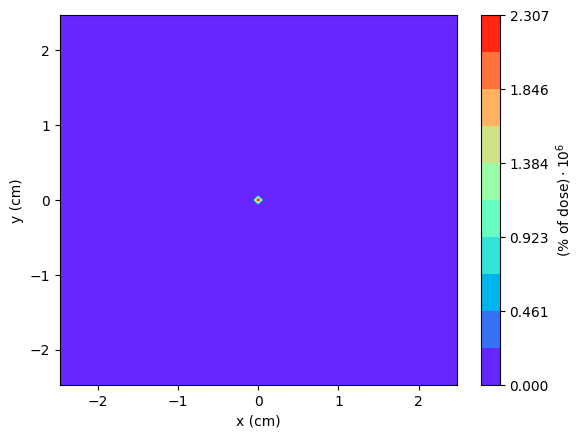

In [12]:
# Now that we have our axes and energy values, we can use matplotlib to generate the plot
fig0, ax0 = plt.subplots()

# This function allows us to map our energy values to a grid
# See https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html
# Note: the parameter "indexing='ij'" is important! If you leave it out, the plot will be abnormally rotated
Xv, Yv = np.meshgrid(X, Y, indexing='ij')

scale = 1e6
contour0 = ax0.contourf(Xv, Yv, energy0/scale, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar0 = fig0.colorbar(contour0, label=r"$(\text{% of dose}) \cdot 10^6$")
ax0.set_xlabel("x (cm)")
ax0.set_ylabel("y (cm)")

While we've successfully made a contour plot, this one doesn't look particularly useful. The source (at the very center) has such a high radiation level that it "washes out" the details of the dose distribution just outside the applicator, which is the area we care about the most. To fix this, we can set all the voxels around the source to have an energy of 0. We do this by setting the parameter `zero_source = True` in the function `countour_energy`. This will also require us to set the parameter `source_rad` to be nonzero - this parameter defines the radius below which voxel have their energies "zeroed."

In [14]:
# Let's zero just the source by setting source_rad = 0.03 cm
# Note that this value is stored in the array source_rad in the "Set parameters" section above
X, Y, energy1, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[0], scale=True, norm_energy=dose_energy, dose=dose, zero_source=True, std_dev=True)

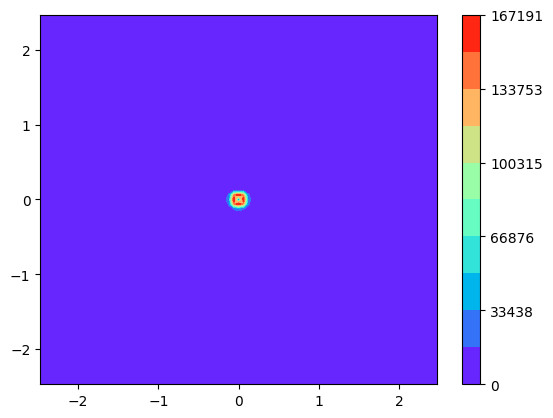

In [15]:
fig1, ax1 = plt.subplots()

# We don't need to recalculate the meshgrids Xv and Yv

contour1 = ax1.contourf(Xv, Yv, energy1, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1)

This looks a little better, but we still can't see much detail outside the applicator. Let's increase `source_rad` to 0.4 cm.

In [16]:
# Set source_rad = 0.4 cm - stored in the array source_rad above
X, Y, energy2, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[4], scale=True, norm_energy=dose_energy, dose=dose, zero_source=True, std_dev=True)

Text(0, 0.5, 'y (cm)')

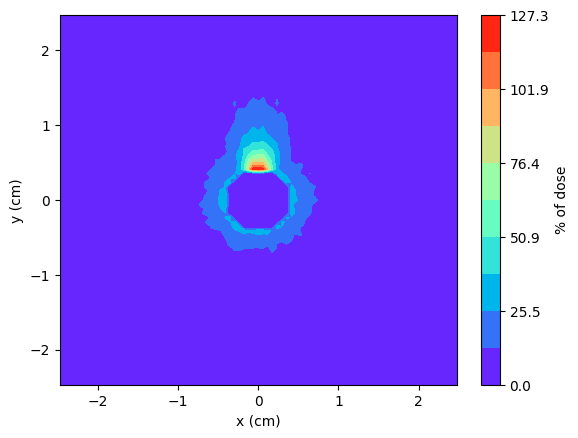

In [17]:
fig2, ax2 = plt.subplots()

contour2 = ax2.contourf(Xv, Yv, energy2, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar2 = fig2.colorbar(contour2, label="% of dose")
ax2.set_xlabel("x (cm)")
ax2.set_ylabel("y (cm)")

Nice! This allows us to see some of the detail just outside the applicator's edge. Note the "jet" of radiation extending outward from the 12 o'clock position. This is entirely expected since we have removed the rod at position 1 (i.e. at 12 o'clock). The highest dose is concentrated just outside the applicator edge. For reference, let's draw the applicator on this plot.

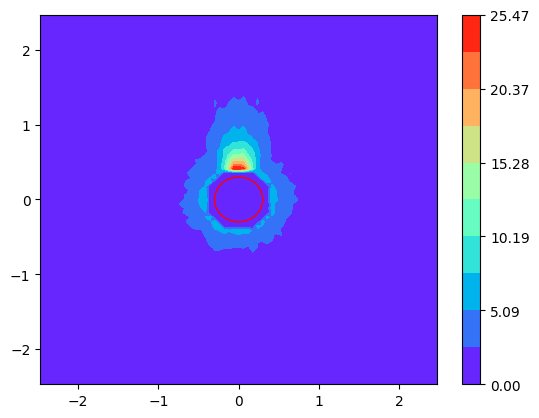

In [11]:
# Regenerate the plot with a red circle indicating the applicator edge
fig2, ax2 = plt.subplots()

contour2 = ax2.contourf(Xv, Yv, energy2, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar2 = fig2.colorbar(contour2)

circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
ax2.add_patch(circle)

We can examine the dose distribution at any region outside the applicator by varying the `source_rad` parameter. For example, here's the dose distribution within 0.8 cm zeroed:

In [12]:
# Set source_rad = 0.8 cm - stored in the array source_rad above
X, Y, energy3, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[8], scale=True, norm_energy=dose_energy, dose=dose, zero_source=True, std_dev=True)

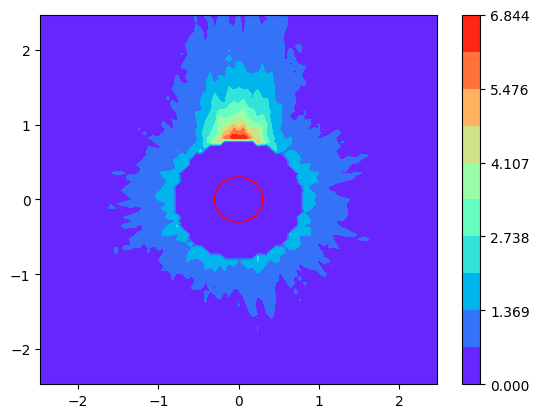

In [13]:
fig3, ax3 = plt.subplots()

contour3 = ax3.contourf(Xv, Yv, energy3, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar3 = fig3.colorbar(contour3)

circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
ax3.add_patch(circle)

The color bar at the side of each plot is currently displaying the radiation dose in Gray (1 Gy = 1 J/kg). This is because we set `scale = True` in the function `contour_energy`, allowing us to scale all voxels to the dose delivered at a specific voxel inside our region of interest. The dose and voxel were defined at the beginning of this section with the parameters `dose = 20` (i.e. 20 Gy) and `dose_point = (0, 0.5)`. Let's change the dosing point and observe how the scale changes.

In [14]:
# Update our dosing point
dose_point_2 = (0, 1.5)

# Extract the energy at the new dose point
dose_energy_2, dose_voxel_2 = extract_norm_energy(mosh, source_plane, const_axis, dose_point_2, bins_mosh, lattice_mosh)

# Our dose will remain 20 Gy

In [15]:
# Use our new dosing point to generate a new contour plot
# We will zero all voxels with radius < 0.4 cm
X, Y, energy4, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[4], scale=True, norm_energy=dose_energy_2, dose=dose, zero_source=True, std_dev=True)

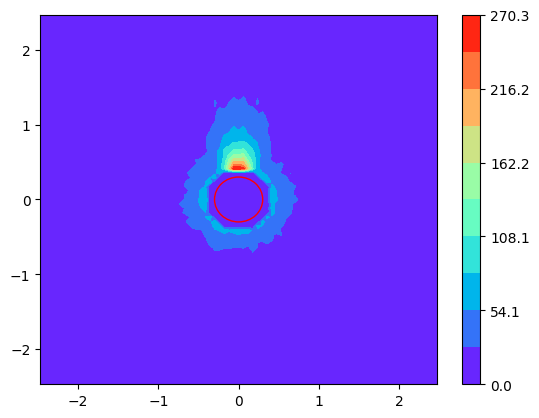

In [16]:
fig4, ax4 = plt.subplots()

contour4 = ax4.contourf(Xv, Yv, energy4, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar4 = fig4.colorbar(contour4)

circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
ax4.add_patch(circle)

The plot looks identical to the previous plot with `source_rad = 0.4`, but the scale has changed. Physically, this means that if we want the point `(0, 1.5)` to have a dose of 20 Gy, the bright red area at the applicator's 12 o'clock will receive 270 Gy of radiation. Likewise, if we want the point `(0, 0.5)` to have a dose of 20 Gy, the same bright red region will only receive about 25 Gy. Although the overall structure of the contour plot does not change, the absolute value of the radiation deposited in each voxel will vary with the dose and the dosing point.

We can also set `scale = False` when running `contour_energy`, which allows us to see the raw output of the TOPAS simulation without scaling:

In [17]:
# Set scale = False
X, Y, energy5, std_dev = contour_energy(mosh, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, const_axis, rngX, rngY, 
                                       source_rad=source_rad[4], scale=False, zero_source=True, std_dev=True)

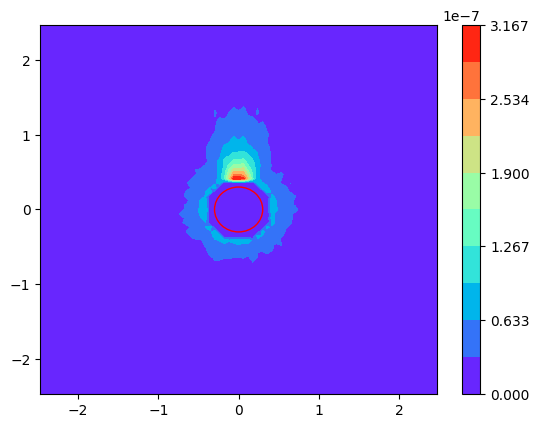

In [18]:
fig5, ax5 = plt.subplots()

contour5 = ax5.contourf(Xv, Yv, energy5, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar5 = fig5.colorbar(contour5)

circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
ax5.add_patch(circle)

You'll notice that the red area now has a dose of approximately $3 \cdot 10^{-7}$ Gy - eight orders of magnitude lower than the plots we were looking at above! This simulation was run with $10^{7}$ histories, which means it simulates an extremely short time interval in the real world - you can think of it as an "instantaneous snapshot" of the applicator-source system. Creating contour plots without scaling preserves the *relative* doses between voxels, but does not give clinically useful information about the absolute dose in our region of interest. Because of this, we usually default to using the scaling feature and assign a dose to a voxel of interest, even if this point does not correspond to an actual tumor (as in the examples above).

## Rotations

After creating a contour plot, we may need to rotate the energy values in the underlying energy matrix to simulate a rotation of the applicator. We can do this with the `rotate_applicator` function from `plotting_functions`.

In [19]:
# Define our angle of rotation
# For this function, the angle must be in degrees (not radians)
rotation = -90

rotated_90 = rotate_applicator(energy2, rotation)

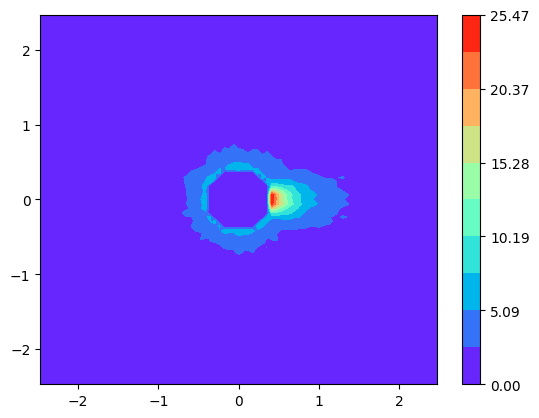

In [20]:
# Plot the rotated distribution
fig12, ax12 = plt.subplots()

contour12 = ax12.contourf(Xv, Yv, rotated_90, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar12 = fig12.colorbar(contour12)

Note that if we rotate by an angle that is not along one of the axes, we lose some information because we are trying to impose a continuous rotation on a discrete grid. Consider the plot when we set `rotation = 40`:

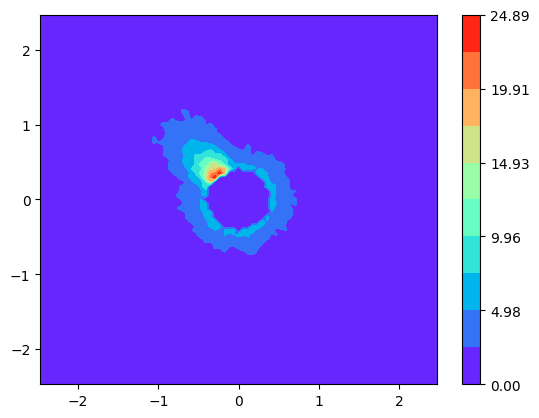

In [21]:
rotation_2 = 40
rotated_45 = rotate_applicator(energy2, rotation_2)

fig13, ax13 = plt.subplots()
contour13 = ax13.contourf(Xv, Yv, rotated_45, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar13 = fig13.colorbar(contour13)

Notice that this distribution looks "rougher" compared to the original distribution and the applicator rotated by 90 degrees. As the density of voxels increases, the error with rotation decreases (in general, $\text{err} \rightarrow 0$ as $\text{voxels} \rightarrow \infty$). We're currently working to quantify how much the rotation error changes as we increase the number of voxels, since this will also increase our computation time for simulations. 

## Creating one-dimensional plots - constant angle

After creating a contour plot, we may want to analyze the dose more quantitatively by examining the dose along a one-dimensional line with either radius or angle held constant. This section outlines the basic process for creating these plots with functions in `plotting_functions`.

The simplest case is plotting the dose at a constant angle, so we'll consider this example first.

In [22]:
# First, we define the angle along which we want to plot and the error for our plot.
# We must provide an error value because we are applying a continuous angle to a discrete
# system, so there will necessarily be some variation when selecting voxels that lie 
# along a particular line.
theta = pi/2
error = 0.025 # cm

# One additional note on error - in general, we can use a much lower error (approx. 0.001 cm) when extracting
# energy along the x- or y-axes (theta = pi or theta = pi/2). Use a larger error for angles not along the
# x- or y-axes or when you are extracting energy at constant radius. See the appendix for more information.

# We can plug these values into the function energy_along_theta, which extracts the energy from voxels along theta
# Note that the input angle theta must be in the range (0, pi] - use theta = pi to plot along the x-axis
# Note that we do not use the second output - we'll consider this output later
linear_energy, __ = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error, scale=True, norm_energy=dose_energy, dose=dose)

The matrix `linear_energy` returned by `energy_along_theta` has four columns: `r`, `theta`, `energy`, and `std_dev`. Since we are plotting at constant angle, all of the `theta` values should be either `pi/2 = 1.57` or `-pi/2 = -1.57`. However, since there is some error in selecting voxels along the line with `theta = pi/2`, these values may vary by `+/- error`.

One additional note: if the TOPAS output file did not contain standard deviation information, `linear_energy` will only have three columns.

In [23]:
# Uncomment to inspect the theta column of linear_energy
#print(linear_energy) 

Our next step is to convert the matrix `linear_energy` into a format that is amenable to plotting via matplotlib.

In [24]:
# We use the function plotter_1D to return arrays we can use for plotting
x_radius, y_energy, std_dev_sum, std_dev_mean, __ = plotter_1D(linear_energy, ind_var=0, plot_rng=(0,0), std_dev=True, num_Hx=1e7)

# Note that we dump the last output - it has been deprecated and will be removed in the next version of the software

The parameter `ind_var` sets the independent variable (x-axis) of the plot, with `0 = radius` and `1 = angle`. Since we generated `linear_energy` with constant `theta`, we set our independent variable to be the radius. We can also specify a plot range; setting `plot_rng=(0,0)` allows us to plot the entire range included in `linear_energy`. Finally, setting `std_dev=True` allows us to calculate the standard deviation of the total energy and mean energy delivered to the voxels of interest.

We can now use matplotlib to generate our first plot of energy vs radius.

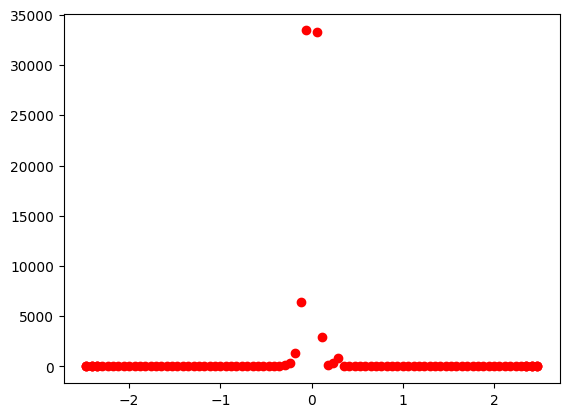

In [25]:
fig6, ax6 = plt.subplots()
ax6.scatter(x_radius, y_energy, color="red")

Unfortunately, this plot has the same problem as our first contour plot - the energy at the source ($r = 0$) completely washes out any detail in the regions we care about (usually $0.3 < r < 1.0$ for an applicator with a radius of 0.3 cm). We can fix this by recomputing our $x$ and $y$ values with `plot_rng=(0.3, 1.0)`:

In [26]:
# Recompute our x and y values with a narrower range for the x-axis
x_radius_2, y_energy_2, std_dev_sum_2, std_dev_mean_2, __ = plotter_1D(linear_energy, ind_var=0, plot_rng=(0.3,1.0), std_dev=True, num_Hx=1e7)

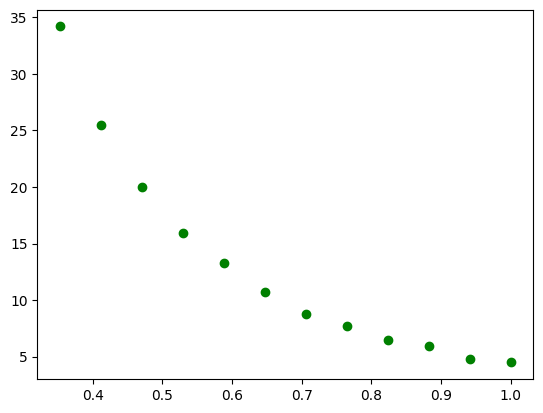

In [27]:
# Plot the new values
fig7, ax7 = plt.subplots()
ax7.scatter(x_radius_2, y_energy_2, color="green")

Much better! This shows an exponential decrease in dose from the applicator edge to $r = 1.0$ cm. We can extend this plot out to $r = 2.0$ cm to see this behavior in more detail:

In [28]:
# Recompute a slightly larger range
x_radius_3, y_energy_3, std_dev_sum_3, std_dev_mean_3, __ = plotter_1D(linear_energy, ind_var=0, plot_rng=(0.3,2.0), std_dev=True, num_Hx=1e7)

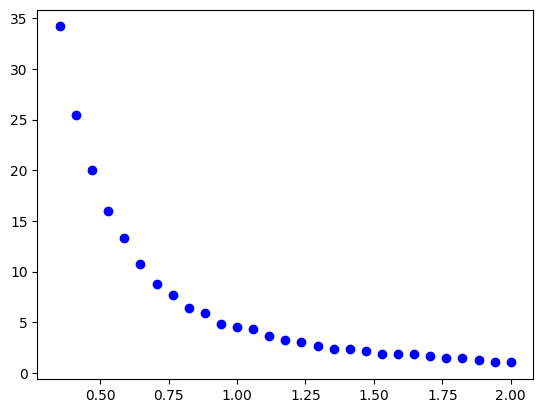

In [29]:
# Plot the new values
fig8, ax8 = plt.subplots()
ax8.scatter(x_radius_3, y_energy_3, color="blue")

We can also add standard deviation values to this plot with the parameter `std_dev_sum`. Note that the values plotted here are *total* energy values, not mean values, so we don't use `std_dev_mean` in this case.

<ErrorbarContainer object of 3 artists>

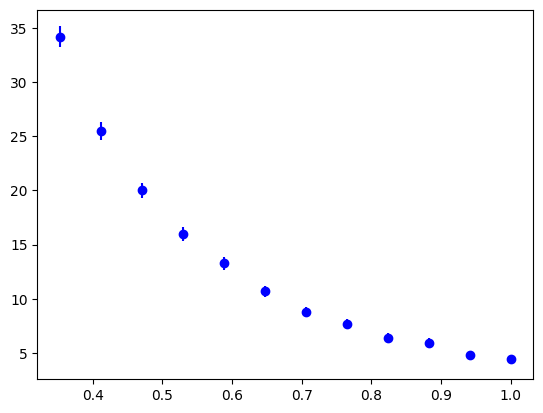

In [30]:
# Plot with standard error bars included
fig9, ax9 = plt.subplots()
ax9.errorbar(x_radius_2, y_energy_2, yerr=std_dev_sum_2, fmt="bo")

## Creating one-dimensional plots - constant radius

We can use the same functions we analyzed above to plot the energy as a function of angle, holding the radius constant. These types of plots are useful when comparing the radiation distribution between two applicator geometries.

To extract energy at constant radius, we set the parameter `radius` in the function `energy_along_theta` to be nonzero. This parameter defines the radius at which energy values will be extracted.

In [31]:
# We'll use the same theta and error that we defined above
# We will examine the energy at radius = applicator_rad + 0.05 cm, i.e. energy just outside the applicator edge
# Note that the second output is no longer dropped!
linear_energy_2, eng_at_const_r = energy_along_theta(mosh, theta, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error, radius=applicator_rad + 0.05, scale=True, norm_energy=dose_energy, dose=dose)

In [32]:
# Uncomment to inspect the columns of eng_at_const_r
# You should see radius = 0.35 +/- error (first column)
#print(eng_at_const_r)

In [33]:
# After this, the process is identical to the one we followed above
# Note that we dump the standard dev values since we are not using them here
x_theta_4, y_energy_4, __, __, __ = plotter_1D(eng_at_const_r, ind_var=1, plot_rng=(0,0))

Note that in the previous cell, we set `ind_var=1` to tell the function that our independent variable is now angle, not radius.

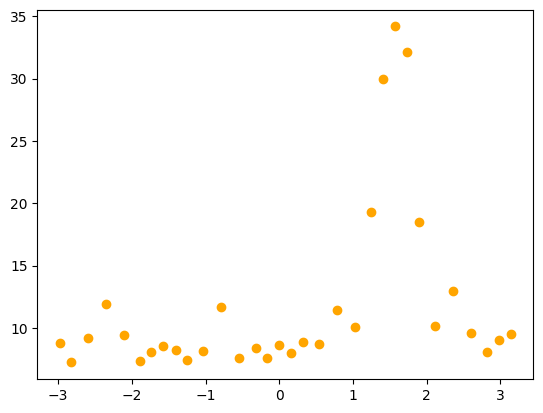

In [34]:
fig10, ax10 = plt.subplots()
ax10.scatter(x_theta_4, y_energy_4, color="orange")

Note that the x-axis is angle (measured in radians). The energy peak of about 35 Gy is at `theta = 1.57`, corresponding to `pi/2` as expected.

## Creating one-dimensional plots - averaging

The function `average_energy` allows us to average the energy values along `theta` and `theta - pi` to smooth out statistical fluctuations in the dose distribution. You should only use this function on dose distributions that are symmetric about $r = 0$. Because of this, we can't use the energy profile along `theta = pi/2` that we analyzed in the previous sections, as this distribution is asymmetrical (since the rod at 12 o'clock is removed). We'll generate a symmetrical distribution below and average both sides.

In [35]:
# Extract energy along x-axis
# Recall that we set theta = pi to analyze the x-axis, NOT theta = 0
theta_x = pi

# Note the value of the parameter err in this call - we set it to 0.001 (not 0.025)
# since we are plotting along the x-axis
linear_energy_3, __ = energy_along_theta(mosh, theta_x, (bins_mosh, bins_mosh), dose_grid_half_mosh, source_plane, 
                                         err=0.001, scale=True, norm_energy=dose_energy, dose=dose)

In [36]:
# Average the energy on either side of r = 0
eng_averaged = average_energy(linear_energy_3)

In [37]:
# Our output eng_averaged has columns (r, theta, average_energy)
# We can use the function plotter_1D to set up arrays for plotting
x_avg, y_avg, __, __, __ = plotter_1D(eng_averaged, plot_rng=(0.3, 1.0))

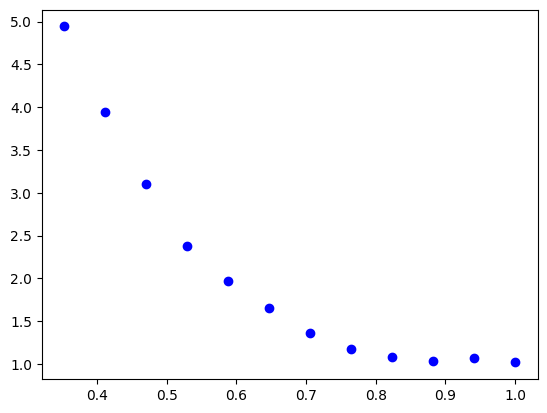

In [38]:
fig11, ax11 = plt.subplots()
ax11.scatter(x_avg, y_avg, color="blue")

Note that the energy values are lower than the plots above because we are plotting along the x-axis (i.e. `theta = pi`), away from the open 12 o'clock position of the applicator where the dose is highest.

## Appendix - selecting the parameter `err`

We mentioned earlier that a parameter `err` is necessary when plotting along angles that are not `pi/2`, `pi`, or `3*pi/2` or when plotting the energy at constant radius. This is because our dosing space is a discrete grid but we are attempting to extract the energy along a continuous angle (or at a continuous radius). Selecting `err` may occasionally require some trial and error to obtain results that make sense and do not throw an error when running the plotting software. In this section, we'll walk through some best practices for selecting this parameter.

### Selecting `err` - plotting along $\theta = n\pi/2$ for $n \in \mathbb{Z}$

When we extract the energy along an angle that is a multiple of `pi/2`, we can exactly identify the voxels that lie along the angle and extract energy values with essentially no error. For example, let's set `err = 0.001` and attempt to extract energy from the angle `theta = pi/2`:

In [39]:
theta1 = pi/2
error1 = 0.001

linear_energy1, __ = energy_along_theta(mosh, theta1, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error1, scale=True, norm_energy=dose_energy, dose=dose)

In [40]:
# Inspect the number of voxels contained within the output linear_energy
print("# voxels along pi/2 = " + str(np.shape(linear_energy1)[0]))

# voxels along pi/2 = 84


This should make sense - our dosing grid is 85 x 85, so the above function has extracted the 84 voxels with `theta = pi/2`. Note that the voxel at the very center of the dosing region (with original coordinate `(0, 0)`) is not included since it was mapped to `(r, theta) = (0, 0)` during the Cartesian --> polar transformation.

Let's try the same operation with `err = 0.00001`.

In [41]:
error2 = 0.00001

linear_energy2, __ = energy_along_theta(mosh, theta1, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error2, scale=True, norm_energy=dose_energy, dose=dose)

In [42]:
# Inspect the number of voxels contained within the output linear_energy
print("# voxels along pi/2 = " + str(np.shape(linear_energy2)[0]))

# voxels along pi/2 = 84


We've decreased the error by 2 orders of magnitude, but the number of extracted voxels has remained constant. We can keep decreasing the error until we reach the limit of irrational floating-point number representation on our computers. This occurs at about the 16th decimal place:

In [43]:
# Observe representations of pi/2 in linear_energy and the math module
print(linear_energy[0][1])
print(-pi/2)

-1.5946013529799665
-1.5707963267948966


In [44]:
# First, run this cell with error3 = 1e-15
# Then run with error3 = 1e-16
error3 = 1e-16

linear_energy3, __ = energy_along_theta(mosh, theta1, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error3, scale=True, norm_energy=dose_energy, dose=dose)

# Inspect the number of voxels contained within the output linear_energy
print("# voxels along pi/2 = " + str(np.shape(linear_energy3)[0]))

# voxels along pi/2 = 0


Running the above cell with `error3 = 1e-15` results in the extraction of 84 voxels as expected, but setting `error3 = 1e-16` results in the extraction of *no* voxels. This just tells us that there are limits to the representation of irrational floating-point numbers on our machine, and decreasing the parameter `error` below this precision makes it impossible for us to select voxels at any angle.

In summary, for angles that are multiples of `pi/2`, you can set the error to essentially any value above `1e-16`. We recommend setting `err = 0.001`.

### Selecting `err` - plotting along arbitrary $\theta$

How can we select `err` when we want to extract the energy along an arbitrary angle? 

1. First quadrant: $r = 42/\cos{\theta}$
2. Second quadrant: $r = 42/\cos{(\pi - \theta)}$

Next problem to address - why are angles along pi/4 returning 84 voxels? This shouldn't be the case based on my math - should be closer to 2*sqrt(42^2 + 42^2) since we're working on a rectangular grid

Can I make a contour plot precisely identifying the voxels with theta = pi/4? This would allow me to visualize exactly which voxels are selected + troubleshoot accordingly

In [142]:
# Let's rotate along an arbitrary angle but use error1 = 0.001 above
theta2 = pi/6
error_arb = 0.05
linear_energy4, __ = energy_along_theta(mosh, theta2, (bins_mosh, bins_mosh), dose_grid_half_mosh, 
                                       source_plane, err=error_arb, scale=True, norm_energy=dose_energy, dose=dose)

In [143]:
# Inspect the number of voxels contained within the output linear_energy
print("# voxels along pi/4 = " + str(np.shape(linear_energy4)[0]))

# voxels along pi/4 = 240


In [144]:
x_radius_4, y_energy_4, __, __, __ = plotter_1D(linear_energy4, ind_var=0, plot_rng=(-1.0,1.0), std_dev=True, num_Hx=1e7)
print(np.shape(x_radius_4))

(26,)


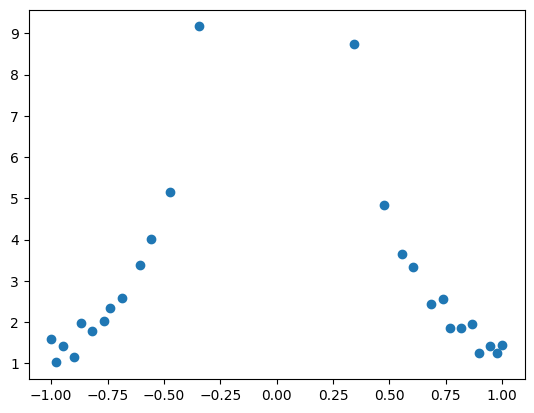

In [145]:
fig, ax = plt.subplots()
ax.scatter(x_radius_4, y_energy_4)